# Mock Interview: Predicting News Popularity

## Objective

Six hours after a news article is published, predict its **Facebook share count at 48 hours (`TS144`)**.

Make one prediction per article across four topics: Economy, Microsoft, Obama, and Palestine.

## Dataset

All files are in [news_popularity/data/Data/](/Users/gracie/Documents/job_interviews/coding_problems/squarepoint/news_popularity/data/Data/).

### Article information: `News_Final.csv`

| Column | Description |
|---|---|
| `IDLink` | Article identifier used to match records across files. |
| `Title` | Article title. |
| `Headline` | Additional headline text from the source; may include an introductory snippet. |
| `Source` | News outlet that published the article. |
| `Topic` | Topic used to collect the article. |
| `PublishDate` | Publication date and time. |
| `SentimentTitle` | Precomputed sentiment score for the title. |
| `SentimentHeadline` | Precomputed sentiment score for the headline text. |
| `Facebook` | Final recorded Facebook popularity value. |
| `GooglePlus` | Final recorded Google+ popularity value. |
| `LinkedIn` | Final recorded LinkedIn popularity value. |

### Share histories: four topic files

- `Facebook_Economy.csv`
- `Facebook_Microsoft.csv`
- `Facebook_Obama.csv`
- `Facebook_Palestine.csv`

Each file contains `IDLink` and `TS1`–`TS144`.

| Columns | Description | Role |
|---|---|---|
| `IDLink` | Article identifier matching `News_Final.csv`. | Join key |
| `TS1`–`TS18` | Share-count observations at 20-minute intervals during the first six hours. | Available inputs |
| `TS19`–`TS143` | Observations after six hours and before the final observation. | Exclude from inputs |
| `TS144` | Share count at 48 hours. | Prediction target |

The observations are **share-count snapshots**, not shares gained within each interval. In the share-count fields, `-1` indicates an unavailable observation.

## Tasks

1. **Prepare the data.** Combine the topic files and match articles using `IDLink`. Check missing values, duplicate IDs, and unmatched records. Explain your handling decisions.
2. **Explore the data.** Examine the target distribution and potentially useful predictors. Include a few informative plots.
3. **Build models.** Establish a simple baseline and train at least one predictive model.
4. **Evaluate performance.** Split articles chronologically into training, validation, and test sets. Use **RMSLE** as the primary metric and report **MAE** in shares.
5. **Interpret the results.** Compare against the baseline, examine errors, and explain limitations.

## Constraints

- Use only information available by six hours after publication.
- Exclude the final `Facebook`, `GooglePlus`, and `LinkedIn` columns from model inputs.
- Do not assume `IDLink` is unique without checking.
- Fit preprocessing on training data and use validation data for model selection.
- Reserve test data for the final evaluation.

## Deliverable

A reproducible Python notebook with readable code, brief explanations, model results, and a short conclusion. Add a one- or two-sentence caption below each plot explaining its main finding.

## Data Cleaning

In [171]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [172]:
df_final = pd.read_csv('Data/News_Final.csv')
df_econ = pd.read_csv('Data/Facebook_Economy.csv')
df_oba = pd.read_csv('Data/Facebook_Obama.csv')
df_micro = pd.read_csv('Data/Facebook_Microsoft.csv')
df_pal = pd.read_csv('Data/Facebook_Palestine.csv')

In [173]:
df_final = df_final.drop(columns=["Facebook", "GooglePlus", "LinkedIn"])

duplicates

In [174]:
# keep=False shows all rows with repeated IDs, including the first occurrence
df_final.loc[df_final["IDLink"].duplicated(keep=False)].sort_values("IDLink")

,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline
31,28854.0,Buffett: Politicians 'Dead Wrong' on Economy,Warren Buffett has a message for presidential ...,The Wall Street Journal,economy,2016-02-28 19:17:00,0.051031,-0.037921
44496,28854.0,Buffett: Politicians 'Dead Wrong' on Economy,Warren Buffett has a message for presidential ...,The Wall Street Journal,economy,2016-02-28 19:17:00,0.051031,-0.037921
6,80690.0,"Monday, 29 Feb 2016","RAMALLAH, February 25, 2016 (WAFA) - Palestine...",NaN,palestine,2016-02-28 14:03:00,0.000000,-0.005906
44426,80690.0,"Monday, 29 Feb 2016","RAMALLAH, February 25, 2016 (WAFA) - Palestine...",NaN,palestine,2016-02-28 14:03:00,0.000000,-0.005906
111,80994.0,"Tuesday, 1 Mar 2016","RAMALLAH, February 29, 2016 (WAFA) - The Gover...",NaN,palestine,2016-03-01 00:15:00,-0.243068,0.048546
44944,80994.0,"Tuesday, 1 Mar 2016","RAMALLAH, February 29, 2016 (WAFA) - The Gover...",NaN,palestine,2016-03-01 00:15:00,-0.243068,0.048546
56,81052.0,"Monday, 29 Feb 2016","RAMALLAH, February 29, 2016 (WAFA) - The Gover...",NaN,palestine,2016-03-01 09:29:00,0.000000,0.048546
45122,81052.0,"Monday, 29 Feb 2016","RAMALLAH, February 29, 2016 (WAFA) - The Gover...",NaN,palestine,2016-03-01 09:29:00,0.000000,0.048546


In [175]:
df_final = df_final.drop_duplicates(subset="IDLink", keep="first")

In [176]:
df_micro = df_micro.drop(columns=df_micro.loc[:, "TS19":"TS143"].columns)
df_econ = df_econ.drop(columns=df_econ.loc[:, "TS19":"TS143"].columns)
df_oba = df_oba.drop(columns=df_oba.loc[:, "TS19":"TS143"].columns)
df_pal = df_pal.drop(columns=df_pal.loc[:, "TS19":"TS143"].columns)

In [177]:
ts_columns = df_micro.loc[:, "TS1":"TS18"].columns.tolist() + ["TS144"]
df_micro[ts_columns] = df_micro[ts_columns].replace(-1, float("nan"))
df_econ[ts_columns] = df_econ[ts_columns].replace(-1, float("nan"))
df_oba[ts_columns] = df_oba[ts_columns].replace(-1, float("nan"))
df_pal[ts_columns] = df_pal[ts_columns].replace(-1, float("nan"))

In [178]:
print('number of duplicates:', df_pal["IDLink"].duplicated().sum())
print('number of nulls in final:', df_final.isna().sum().sum())
print('number of nulls in econ:', df_econ.isna().sum().sum())
print('number of rows in econ that are all nas:', df_econ.loc[:, "TS1":"TS144"].isna().all(axis=1).sum())
print('number of nulls in micro:', df_micro.isna().sum().sum())
print('number of rows in micro that are all nas:', df_micro.loc[:, "TS1":"TS144"].isna().all(axis=1).sum())
print('number of nulls in obama:', df_oba.isna().sum().sum())
print('number of rows in obama that are all nas:', df_oba.loc[:, "TS1":"TS144"].isna().all(axis=1).sum())
print('number of nulls in pal:', df_pal.isna().sum().sum())
print('number of rows in pal that are all nas:', df_pal.loc[:, "TS1":"TS144"].isna().all(axis=1).sum())
print('col null counts of final_df:', df_final.isna().sum())
df_final.loc[df_final.isna().any(axis=1)].head(5)

number of duplicates: 0
number of nulls in final: 291
number of nulls in econ: 352968
number of rows in econ that are all nas: 567
number of nulls in micro: 229353
number of rows in micro that are all nas: 392
number of nulls in obama: 283254
number of rows in obama that are all nas: 403
number of nulls in pal: 73846
number of rows in pal that are all nas: 165
col null counts of final_df: IDLink                 0
Title                  0
Headline              15
Source               276
Topic                  0
PublishDate            0
SentimentTitle         0
SentimentHeadline      0
dtype: int64


,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline
6,80690.0,"Monday, 29 Feb 2016","RAMALLAH, February 25, 2016 (WAFA) - Palestine...",NaN,palestine,2016-02-28 14:03:00,0.000000,-0.005906
56,81052.0,"Monday, 29 Feb 2016","RAMALLAH, February 29, 2016 (WAFA) - The Gover...",NaN,palestine,2016-03-01 09:29:00,0.000000,0.048546
111,80994.0,"Tuesday, 1 Mar 2016","RAMALLAH, February 29, 2016 (WAFA) - The Gover...",NaN,palestine,2016-03-01 00:15:00,-0.243068,0.048546
350,62254.0,Human rights situation in Palestinian territor...,In a special meeting convened by the UN Human ...,NaN,palestine,2015-10-28 17:24:00,-0.228299,-0.124931
409,62258.0,Japan Contributes $5.73M To UNRWA’s Food Assis...,"JERUSALEM, October 31, 2015 (WAFA) – The Japan...",NaN,palestine,2015-10-31 04:30:00,0.166667,-0.042878


In [179]:
df_micro.loc[df_micro.isna().loc[:, 'TS1':'TS144'].all(axis=1)].head(5)

,IDLink,TS1,TS2,TS3,TS4,TS5,TS6,TS7,TS8,TS9,TS10,TS11,TS12,TS13,TS14,TS15,TS16,TS17,TS18,TS144
20,121,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,131,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
36,140,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
45,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
46,172,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [180]:
print('number of unique ids in final:', df_final['IDLink'].nunique())
print('number of unique ids in micro:', df_micro['IDLink'].nunique())
print('number of unique ids in econ:', df_econ['IDLink'].nunique())
print('number of unique ids in obama:', df_oba['IDLink'].nunique())
print('number of unique ids in pal:', df_pal['IDLink'].nunique())
print(df_final['IDLink'].nunique() - (df_micro['IDLink'].nunique() + df_econ['IDLink'].nunique() + df_oba['IDLink'].nunique() + df_pal['IDLink'].nunique()))

number of unique ids in final: 93235
number of unique ids in micro: 18531
number of unique ids in econ: 29928
number of unique ids in obama: 27015
number of unique ids in pal: 7687
10074


In [181]:
df_stacked = pd.concat([df_econ, df_micro, df_oba, df_pal])
df = df_final.merge(df_stacked, on='IDLink', how='outer')
print(df.shape)
display(df.describe())

(93235, 27)


,IDLink,SentimentTitle,SentimentHeadline,TS1,TS2,TS3,TS4,TS5,TS6,TS7,...,TS10,TS11,TS12,TS13,TS14,TS15,TS16,TS17,TS18,TS144
count,93235.000000,93235.000000,93235.000000,11622.000000,16284.000000,19894.000000,25180.000000,26368.000000,27353.000000,30048.000000,...,33851.000000,34687.000000,35488.000000,37089.000000,37825.000000,38482.000000,40013.000000,40665.000000,41352.000000,81634.000000
mean,51559.952368,-0.005410,-0.027495,10.757873,11.628654,15.951593,18.860087,21.001327,22.971703,25.306942,...,32.553632,34.692161,36.688655,39.130119,41.336973,43.537914,45.813386,47.560211,49.421503,129.367506
std,30391.183566,0.136432,0.141967,60.042053,60.110452,350.943499,320.050726,314.819595,311.207771,301.178004,...,296.031417,296.335506,296.894178,297.144173,299.894167,303.478978,305.042172,307.376197,310.324154,661.193274
min,1.000000,-0.950694,-0.755433,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,24300.500000,-0.079057,-0.114576,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,52274.000000,0.000000,-0.026064,1.000000,2.000000,2.000000,2.000000,3.000000,3.000000,3.000000,...,4.000000,4.000000,4.000000,4.000000,4.000000,4.000000,5.000000,5.000000,5.000000,8.000000
75%,76583.500000,0.064277,0.059731,5.000000,6.000000,7.000000,9.000000,10.000000,11.000000,12.000000,...,15.000000,16.000000,17.000000,18.000000,19.000000,19.000000,20.000000,21.000000,22.000000,44.000000
max,104802.000000,0.962354,0.964646,2451.000000,2537.000000,48711.000000,48711.000000,48711.000000,48711.000000,48711.000000,...,48711.000000,48711.000000,48711.000000,48711.000000,48711.000000,48711.000000,48711.000000,48711.000000,48711.000000,49211.000000


In [182]:
print('shape of df:', df.shape)
print('number of nulls per col:', df.isna().sum())
print('number of nulls in total:', df.isna().sum().sum())
print('number of rows that have all nulls in TS:', df.loc[:, "TS1":"TS18"].isna().all(axis=1).sum())

shape of df: (93235, 27)
number of nulls per col: IDLink                   0
Title                    0
Headline                15
Source                 276
Topic                    0
PublishDate              0
SentimentTitle           0
SentimentHeadline        0
TS1                  81613
TS2                  76951
TS3                  73341
TS4                  68055
TS5                  66867
TS6                  65882
TS7                  63187
TS8                  62261
TS9                  61406
TS10                 59384
TS11                 58548
TS12                 57747
TS13                 56146
TS14                 55410
TS15                 54753
TS16                 53222
TS17                 52570
TS18                 51883
TS144                11601
dtype: int64
number of nulls in total: 1131118
number of rows that have all nulls in TS: 51883


Drop NaN's

In [183]:
df = df.dropna(subset=df.loc[:, "TS1":"TS18"].columns, how='all')
df = df.dropna(subset=["TS144"])
print(df.shape)
print(df.isna().sum().sum())
print(df.isna().sum())

(41352, 27)
185332
IDLink                   0
Title                    0
Headline                 0
Source                   0
Topic                    0
PublishDate              0
SentimentTitle           0
SentimentHeadline        0
TS1                  29730
TS2                  25068
TS3                  21458
TS4                  16172
TS5                  14984
TS6                  13999
TS7                  11304
TS8                  10378
TS9                   9523
TS10                  7501
TS11                  6665
TS12                  5864
TS13                  4263
TS14                  3527
TS15                  2870
TS16                  1339
TS17                   687
TS18                     0
TS144                    0
dtype: int64


change time to pd time format and sort the rows

In [ ]:
df["PublishDate"] = pd.to_datetime(df["PublishDate"])
df = df.sort_values(["PublishDate", "Title"]).reset_index(drop=True)
df.head()

,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline,TS1,TS2,...,TS10,TS11,TS12,TS13,TS14,TS15,TS16,TS17,TS18,TS144
24,26.0,Five reasons why a Fed liftoff won't cause the...,"Harris outlined five reasons why """"""Fedexodus,...",Financial Post,economy,2015-11-09 19:40:11,-0.072169,0.409159,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,4.0
108,110.0,"McDonald's, Microsoft A Sell For Retail Invest...",Retail investors were net sellers of stocks in...,Forbes,microsoft,2015-11-09 19:40:16,-0.031250,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.0,8.0
47,49.0,Why We Need a Fuel Economy Sticker for Buildings,We use labels to advertise the fuel economy of...,Greentech Media,economy,2015-11-09 20:40:12,-0.211806,0.000000,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2.0,2.0,2.0,2.0,7.0
142,144.0,"Facebook Inc Battles Apple Inc, Microsoft Corp...","In doing so, the social networking giant will ...",Business Finance News,microsoft,2015-11-09 20:40:18,0.037689,0.130322,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,1.0
19,20.0,Market Slides on Concerns of Cooling Global Ec...,The stock market stumbled Monday as investors ...,New York Times,economy,2015-11-09 21:40:10,0.044194,-0.228747,NaN,NaN,...,NaN,NaN,17.0,17.0,17.0,17.0,17.0,17.0,17.0,19.0


In [185]:
df.loc[df["Title"].duplicated(keep=False)].drop(columns=["IDLink", "Source", "PublishDate"]).groupby("Title").nunique(dropna=True).eq(1).all(axis=1)

Title
#14. Palestine                                                              True
#GivingTuesday Founder 92Y and Founding Partners Blackbaud ...             False
$2 gasoline not jump-starting economy                                      False
$50 oil shouldn't pose major threat to consumers, economy                  False
$58.00 donated in past month                                               False
                                                                           ...  
Would Negative Rates Help Or Hinder the Economy?                           False
Yellen warns proposed law on Fed would damage US economy                   False
You Don't Know What Obama Said at the Mosque                               False
Yuan firms on improving economy                                            False
I am a Palestinian and I think we can learn a lot from the South ...    False
Length: 1059, dtype: bool

In [186]:
# Select available columns from TS1 to TS44
ts_columns = df.columns[df.columns.str.startswith("TS")]
keys = ["Title", "Topic", "Source"]

counts = df.groupby(keys)[ts_columns].nunique()
conflicts = counts.gt(1)
examples = conflicts.loc[conflicts.any(axis=1)].head(1)
rows = df.set_index(keys).index.isin(examples.index)
display(df.loc[rows].sort_values(keys))

,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline,TS1,TS2,...,TS10,TS11,TS12,TS13,TS14,TS15,TS16,TS17,TS18,TS144
69790,76443.0,$58.00 donated in past month,"Welcome to this Week in Palestine, a service o...",Bay Area Indymedia,palestine,2016-02-06 06:45:38,0.0,-0.052129,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
71024,77738.0,$58.00 donated in past month,"Welcome to this Week in Palestine, a service o...",Bay Area Indymedia,palestine,2016-02-13 14:56:09,0.0,-0.052129,NaN,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0


In [187]:
df.loc[df["Title"].duplicated(keep=False)].sort_values('Title').head()

,IDLink,Title,Headline,Source,Topic,PublishDate,SentimentTitle,SentimentHeadline,TS1,TS2,...,TS10,TS11,TS12,TS13,TS14,TS15,TS16,TS17,TS18,TS144
90211,101697.0,#14. Palestine,"In 2014, Palestine received a total of $497,26...",Coos Bay World,palestine,2016-06-17 03:14:50,0.0,0.016549,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
90193,101679.0,#14. Palestine,"In 2014, Palestine received a total of $497,26...",Santa Maria Times (subscription),palestine,2016-06-17 00:15:53,0.0,0.016549,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
90154,101640.0,#14. Palestine,"In 2014, Palestine received a total of $497,26...",Casper Star-Tribune Online,palestine,2016-06-16 20:35:50,0.0,0.016549,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
90221,101707.0,#14. Palestine,"In 2014, Palestine received a total of $497,26...",Hanford Sentinel,palestine,2016-06-17 04:31:48,0.0,0.016549,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
90196,101682.0,#14. Palestine,"In 2014, Palestine received a total of $497,26...",Glens Falls Post-Star,palestine,2016-06-17 01:25:48,0.0,0.016549,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## EDA

In [188]:
df.groupby('Topic')['PublishDate'].describe()

,count,mean,min,25%,50%,75%,max
Topic,,,,,,,
economy,14317,2016-02-14 10:21:20.992806,2015-11-09 19:40:11,2015-12-24 17:27:17,2016-02-05 06:20:22,2016-04-08 12:23:14,2016-06-20 20:01:06
microsoft,7756,2016-02-14 07:33:19.650593,2015-11-09 19:40:16,2015-12-21 21:19:07.750000,2016-02-05 11:39:30.500000,2016-04-11 14:25:07.500000,2016-06-20 20:40:12
obama,14986,2016-03-11 06:29:12.533565,2015-11-19 17:44:35,2016-01-17 04:44:59.750000,2016-03-10 10:33:35.500000,2016-05-03 17:55:11,2016-07-07 14:20:15
palestine,4293,2016-03-06 19:03:59.266480,2015-11-19 18:44:42,2016-01-11 18:04:57,2016-03-04 13:29:14,2016-04-28 09:22:22,2016-07-07 15:59:22


Train-val-test split

In [189]:
# Derive cutoffs from approximate 70% / 15% / 15% proportions
valid_start = df["PublishDate"].iloc[int(len(df) * 0.70)]
test_start = df["PublishDate"].iloc[int(len(df) * 0.85)]

# Conservative assumption: 48-hour target + 20-minute collection buffer
label_ready = df["PublishDate"] + pd.Timedelta(hours=48, minutes=20)

train = df.loc[label_ready < valid_start].copy()
valid = df.loc[(df["PublishDate"] >= valid_start) & (label_ready < test_start)].copy()
test = df.loc[df["PublishDate"] >= test_start].copy()

# Keep each exact title in only one split
valid = valid.loc[~valid["Title"].isin(train["Title"])].copy()
test = test.loc[~test["Title"].isin(train["Title"])].copy()
test = test.loc[~test["Title"].isin(valid["Title"])].copy()

In [190]:
print('number of training data:', len(train))
print('number of val data:', len(valid))
print('number of testing data:', len(test))

number of training data: 28457
number of val data: 5771
number of testing data: 6192


In [191]:
display(train.groupby('Topic').size()/train['IDLink'].count())
display(valid.groupby('Topic').size()/valid['IDLink'].count())
display(test.groupby('Topic').size()/test['IDLink'].count())

Topic
economy      0.372738
microsoft    0.199002
obama        0.329304
palestine    0.098956
dtype: float64

Topic
economy      0.327153
microsoft    0.200658
obama        0.367701
palestine    0.104488
dtype: float64

Topic
economy      0.246286
microsoft    0.125969
obama        0.501453
palestine    0.126292
dtype: float64

careful about data imbalance here

1. What does popularity look like: histogram of TS144 (might take log)
2. How much do we already know at six hours? TS18 vs TS 144 (might take log)
3. recent growth, e.g. TS18 - TS12. Compare final popularity across low/high growth groups. Tests whether an article's 
momentum matters beyond its current popularity
4. Do topics or publishers differ?
5. How much early history is actually available: plot the missing percentage of TS1-TS18; inspect the first available and compare coverage by topic
6. weekly article counts by topic; 

distribution of log(final shares) and log(48hr-6hr)

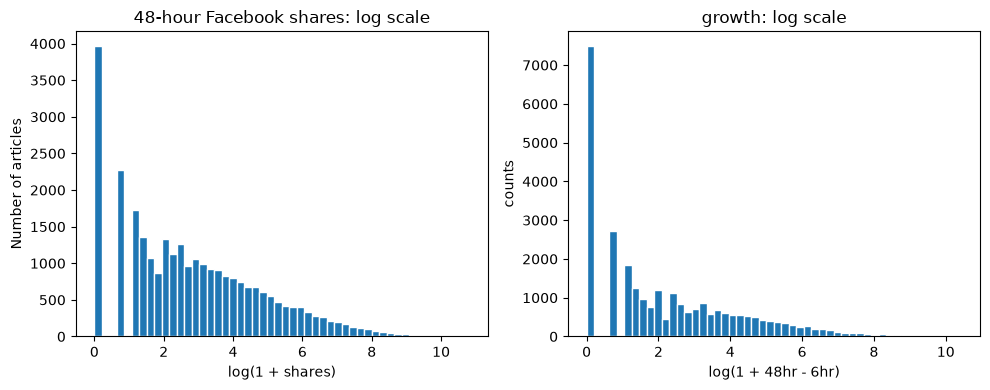

In [192]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# plot the distribution of log change in shares
log_change = np.log1p(train['TS144'] - train['TS18'])

axes[1].hist(log_change, bins=50, edgecolor="white")
axes[1].set_title("growth: log scale")
axes[1].set_xlabel("log(1 + 48hr - 6hr)")
axes[1].set_ylabel("counts")


# plot the distribution of log final shares
shares = train["TS144"].dropna()

axes[0].hist(np.log1p(shares), bins=50, edgecolor="white")
axes[0].set_title("48-hour Facebook shares: log scale")
axes[0].set_xlabel("log(1 + shares)")
axes[0].set_ylabel("Number of articles")

plt.tight_layout()
plt.show()

note: a large concentration near zero and a long right tail

how much do we already know at 6hr

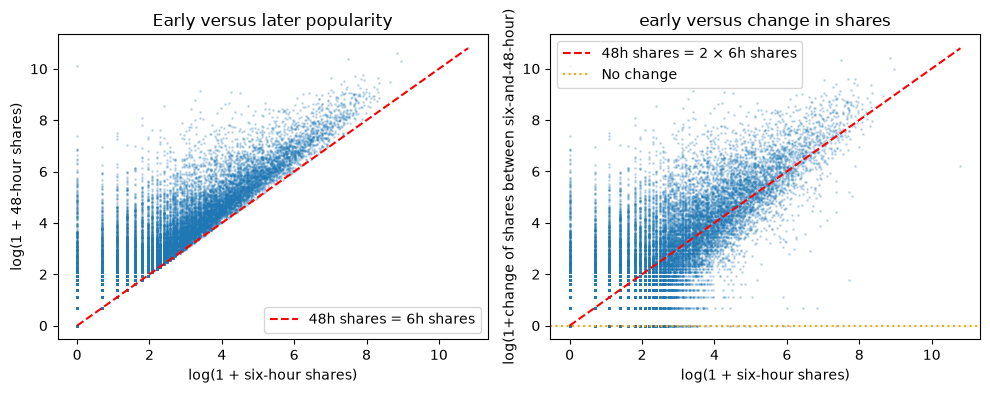

In [193]:
plot_data = train[["TS18", "TS144"]].dropna()

x = np.log1p(plot_data["TS18"])
y = np.log1p(plot_data["TS144"])

fig, ax = plt.subplots(1,2,figsize=(10, 4))

ax[0].scatter(x, y, s=1, alpha=0.2)

# Equality line: no change between 6 and 48 hours
upper = max(x.max(), y.max())
ax[0].plot([0, upper], [0, upper], "r--", label="48h shares = 6h shares")

ax[0].set_xlabel("log(1 + six-hour shares)")
ax[0].set_ylabel("log(1 + 48-hour shares)")
ax[0].set_title("Early versus later popularity")
ax[0].legend()

change = np.log1p(plot_data['TS144'] - plot_data['TS18'])
ax[1].scatter(x,change,s=1,alpha=0.2)

ax[1].plot([0,max(change.max(), x.max())], [0,max(change.max(), x.max())], 'r--',label="48h shares = 2 × 6h shares")
ax[1].axhline(0, color="orange", linestyle=":", label="No change")

ax[1].set_xlabel("log(1 + six-hour shares)")
ax[1].set_ylabel('log(1+change of shares between six-and-48-hour)')
ax[1].set_title('early versus change in shares')

ax[1].legend()


plt.tight_layout()
plt.show()

articles with greater early popularity tend to gain more additional shares afterward.

Text(0.5, 1.0, 'future shares vs recent growth (log scale)')

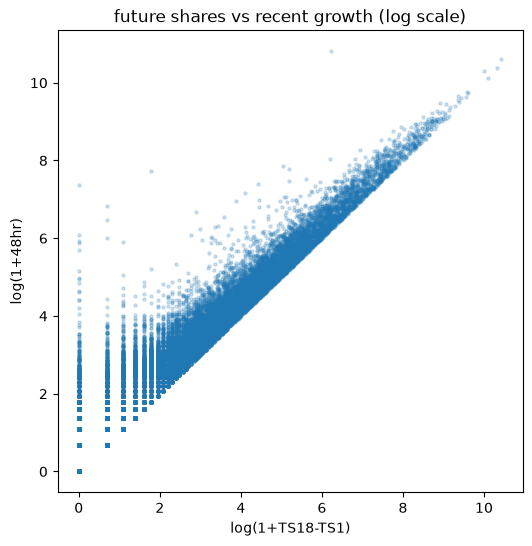

In [194]:
fig, ax = plt.subplots(figsize=(6, 6))
log_recent_change = np.log1p(train['TS18'] - train['TS1'])

ax.scatter(log_change,np.log1p(train['TS144']), s=5,alpha=0.2)
ax.set_xlabel('log(1+TS18-TS1)')
ax.set_ylabel('log(1+48hr)')
ax.set_title('future shares vs recent growth (log scale)')


articles that gained more shares early generally gained more shares later

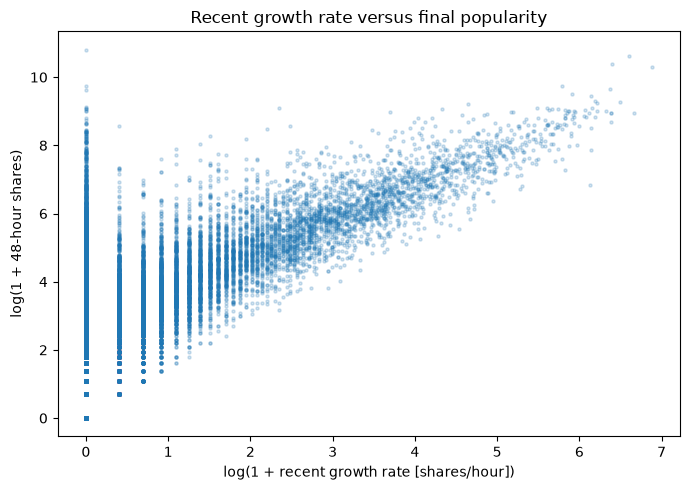

Faster growth between four and six hours tends to accompany higher final popularity. This comparison does not control for six-hour shares.


In [195]:
momentum = train[["TS12", "TS18", "TS144"]].dropna().copy()
# number of extra shares per hour in the recent 2 hours
momentum["recent_rate"] = (momentum["TS18"] - momentum["TS12"]) / 2

# Check before applying log1p
assert (momentum["recent_rate"] >= 0).all(), "Check decreasing counts."

fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(
    np.log1p(momentum["recent_rate"]),
    np.log1p(momentum["TS144"]),
    s=5,
    alpha=0.2
)

ax.set_xlabel("log(1 + recent growth rate [shares/hour])")
ax.set_ylabel("log(1 + 48-hour shares)")
ax.set_title("Recent growth rate versus final popularity")

plt.tight_layout()
plt.show()

print(
    "Faster growth between four and six hours tends to accompany higher "
    "final popularity. This comparison does not control for six-hour shares."
)

Articles gaining shares faster generally achieve greater final popularity. The vertical strip at zero represents articles with no gains between four and six hours; they may still have shares from earlier or later periods

### Distributions by topic

Compare the training articles using the same bins and axes across topics. Each histogram totals 100% within its topic, so larger topics do not automatically have taller bars.

Later growth is `100 × (TS144 / TS18 − 1) / 42`: total percentage growth from six to 48 hours divided by 42 hours, without compounding. It needs a positive six-hour count but does not need an observation before six hours.

In [196]:
# prepares data
# removes rows without a topic final share count
topic_data = train[["Topic", "TS18", "TS144"]].copy()
topic_data = topic_data.dropna(subset=["Topic", "TS144"])
topics = sorted(topic_data["Topic"].unique())
topics

['economy', 'microsoft', 'obama', 'palestine']

In [197]:
# Zero starting counts cannot define percentage growth
topic_data["later_pct_per_hour"] = np.nan
positive_six_hour = topic_data["TS18"] > 0

$$
\text{Later percentage growth per hour}
=
\frac{100(TS144/TS18-1)}{42}
$$

In [198]:
topic_data.loc[positive_six_hour, "later_pct_per_hour"] = (
    100 * (
        topic_data.loc[positive_six_hour, "TS144"]
        / topic_data.loc[positive_six_hour, "TS18"] - 1
    ) / 42
)

In [199]:
topic_data

,Topic,TS18,TS144,later_pct_per_hour
24,economy,2.0,4.0,2.380952
108,microsoft,6.0,8.0,0.793651
47,economy,2.0,7.0,5.952381
142,microsoft,0.0,1.0,NaN
19,economy,17.0,19.0,0.280112
...,...,...,...,...
79621,palestine,44.0,437.0,21.266234
35480,economy,4.0,5.0,0.595238
35485,economy,5.0,47.0,20.000000
35482,economy,38.0,50.0,0.751880


In [200]:
# Check the nonnegative growth assumed by the plots below
assert (topic_data["TS144"] >= 0).all(), "Check negative final share counts."
assert not (topic_data["later_pct_per_hour"] < 0).any(), "Check decreasing share counts."

topic_summary = topic_data.groupby("Topic").agg(
    articles=("TS144", "size"), # size counts every row, including rows with missing values
    median_final_shares=("TS144", "median"),
    growth_articles=("later_pct_per_hour", "count"), # counts only nonmissing values
    median_growth_pct_per_hour=("later_pct_per_hour", "median")
)

print("Training articles:", len(train))
print("Final-share observations:", len(topic_data))
print("Excluded from percentage growth (zero or missing TS18):", (~positive_six_hour).sum())
display(topic_summary.round(2))

Training articles: 28457
Final-share observations: 28457
Excluded from percentage growth (zero or missing TS18): 6103


,articles,median_final_shares,growth_articles,median_growth_pct_per_hour
Topic,,,,
economy,10607,5.0,7577,1.90
microsoft,5663,6.0,4474,1.47
obama,9371,57.0,8517,2.92
palestine,2816,5.0,1786,3.29


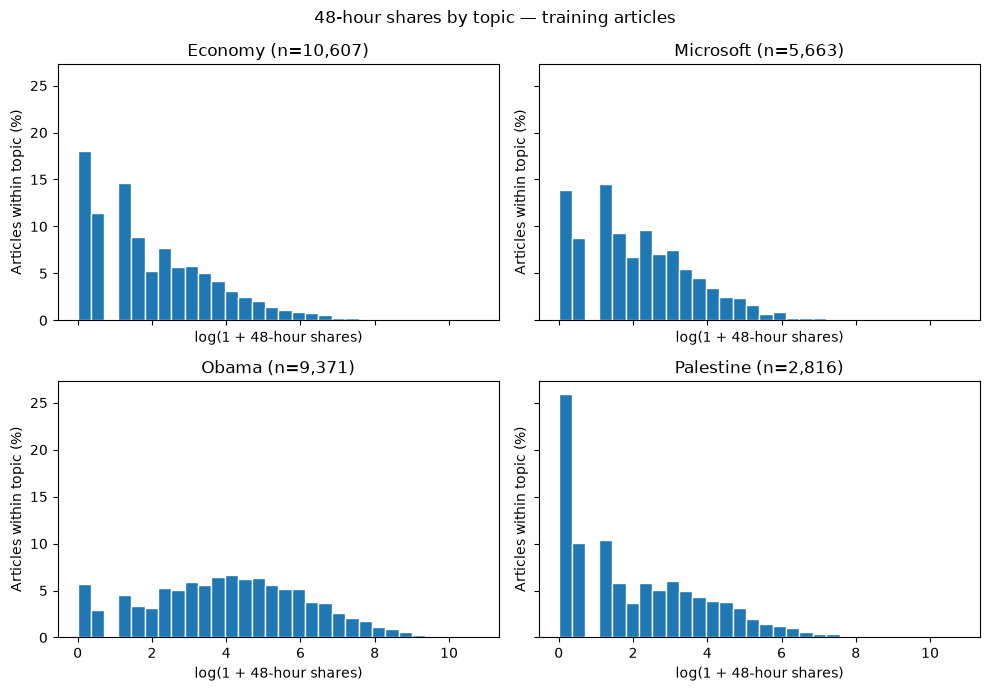

In [201]:
# Common bins and scales make the four distributions comparable
final_bins = np.linspace(0, np.log1p(topic_data["TS144"]).max(), 31)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
fig.suptitle("48-hour shares by topic — training articles")

for ax, topic in zip(axes.flat, topics):
    shares = topic_data.loc[topic_data["Topic"] == topic, "TS144"]
    weights = np.full(len(shares), 100 / len(shares)) # np.full(shape, fill_value) creates an array filled with the same value

    ax.hist(np.log1p(shares), bins=final_bins, weights=weights, edgecolor="white") # if a bin has 20 articles, height is 20 * weight[bin]
    ax.set_title(f"{topic.capitalize()} (n={len(shares):,})")
    ax.set_xlabel("log(1 + 48-hour shares)")
    ax.set_ylabel("Articles within topic (%)")

plt.tight_layout()
plt.show()

The histograms show final share counts, including zeros, on a `log(1 + shares)` scale. Obama articles have a median of 57 shares, compared with 6 for Microsoft and 5 each for Economy and Palestine; every topic has a long right tail.

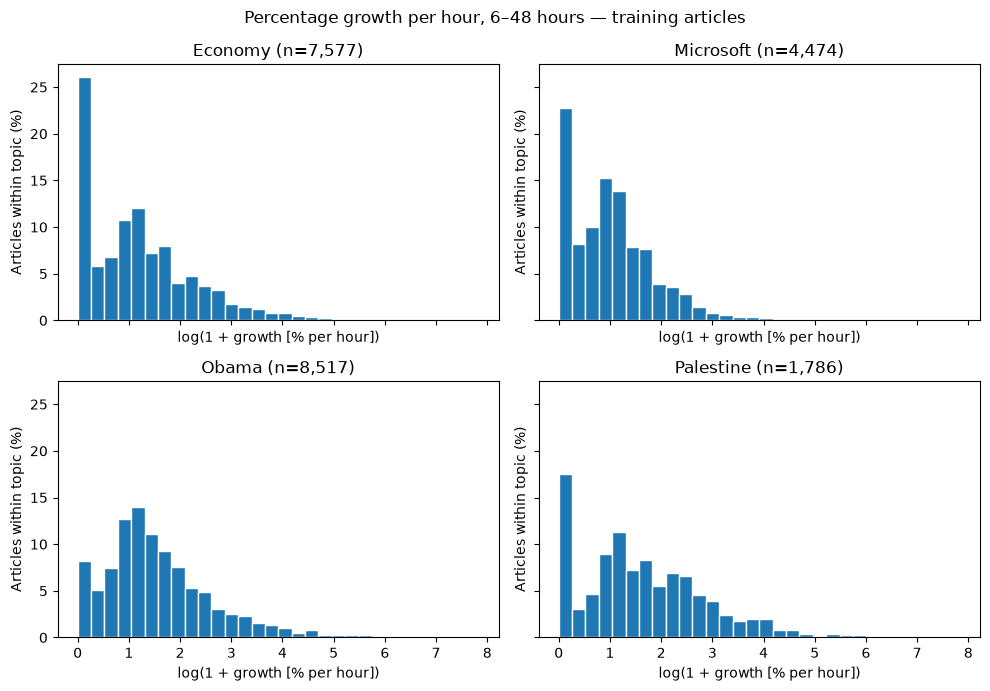

In [202]:
# Use every article with a defined later percentage rate
topic_rates = topic_data.dropna(subset=["later_pct_per_hour"])
growth_bins = np.linspace(0, np.log1p(topic_rates["later_pct_per_hour"]).max(), 31)
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey=True)
fig.suptitle("Percentage growth per hour, 6–48 hours — training articles")

for ax, topic in zip(axes.flat, topics):
    growth = topic_rates.loc[topic_rates["Topic"] == topic, "later_pct_per_hour"]
    weights = np.full(len(growth), 100 / len(growth))

    ax.hist(np.log1p(growth), bins=growth_bins, weights=weights, edgecolor="white")
    ax.set_title(f"{topic.capitalize()} (n={len(growth):,})")
    ax.set_xlabel("log(1 + growth [% per hour])")
    ax.set_ylabel("Articles within topic (%)")

plt.tight_layout()
plt.show()

why log: To prevent a few very large growth rates from stretching the x-axis and squeezing most articles near zero.

Among articles with positive six-hour counts, median later growth is 3.29% per hour for Palestine, 2.92% for Obama, 1.90% for Economy and 1.47% for Microsoft. These descriptive comparisons exclude 6,103 articles with zero six-hour shares, and do not control for differences in starting counts.

1. Palestine has the highest median relative growth; Microsoft has the lowest.
   This concerns growth relative to the six-hour starting count, not the number of additional shares.
2. Obama articles are much less likely to finish without additional shares.
   Only 6.2% have unchanged counts between six and 48 hours, compared with 24% for Economy. I calculated these exact proportions separately—the first histogram bar includes both zero and small positive growth.
3. All topics have long right tails.
   Most articles have modest growth, while a small number grow exceptionally strongly. That makes medians useful for describing a typical article.
4. High percentage growth does not necessarily mean high final popularity.
   In the separate final-share comparison, Obama’s median is 57 shares, versus 5 for Palestine. A small starting count can produce a large percentage increase without a large final count.
The growth comparison excludes 6,103 zero-start articles, while the final-share comparison includes them. These findings suggest topic may help prediction, but they do not establish that topic causes the differences or adds predictive value after accounting for six-hour popularity.

## Feature Creation

In [203]:
early_columns = [f"TS{i}" for i in range(1, 19)]

numeric_columns = early_columns + [
    "SentimentTitle",
    "SentimentHeadline"
]
categorical_columns = ["Topic", "Source"]

def make_features(data):
    features = data[numeric_columns + categorical_columns].copy()
    features[early_columns] = np.log1p(features[early_columns])
    return features

X_train = make_features(train)
X_valid = make_features(valid)
X_test = make_features(test)

y_train = train["TS144"].copy()
y_valid = valid["TS144"].copy()
y_test = test["TS144"].copy()

display(X_train.head(3))

,TS1,TS2,TS3,TS4,TS5,TS6,TS7,TS8,TS9,TS10,...,TS13,TS14,TS15,TS16,TS17,TS18,SentimentTitle,SentimentHeadline,Topic,Source
24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.098612,-0.072169,0.409159,economy,Financial Post
108,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.945910,-0.031250,0.000000,microsoft,Forbes
47,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,1.098612,1.098612,1.098612,1.098612,-0.211806,0.000000,economy,Greentech Media


In [204]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import Ridge

numeric_steps = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler())
])

categorical_steps = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_steps, numeric_columns),
    ("categorical", categorical_steps, categorical_columns)
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("regression", Ridge(alpha=1.0, solver="lsqr"))
])

In [205]:
from sklearn.metrics import root_mean_squared_log_error

# Learn preprocessing and regression using training data only
model.fit(X_train, np.log1p(y_train))

# Convert predictions back to nonnegative share counts
valid_predictions = np.expm1(model.predict(X_valid))
valid_predictions = np.maximum(valid_predictions, 0)

# Baseline: assume no additional shares after six hours
baseline_predictions = valid["TS18"]

baseline_rmsle = root_mean_squared_log_error(
    y_valid, baseline_predictions
)
model_rmsle = root_mean_squared_log_error(
    y_valid, valid_predictions
)

print(f"Baseline validation RMSLE: {baseline_rmsle:.4f}")
print(f"Ridge validation RMSLE:    {model_rmsle:.4f}")

Baseline validation RMSLE: 1.0260
Ridge validation RMSLE:    0.6969


## Compare other models

Use the same features and chronological validation split for every model. Select using **RMSLE**; also report MAE and RMSE in shares. Lower is better for all three metrics.

- **Ridge:** already fitted to `log1p(TS144)` above.
- **Random forest:** fit `log1p(TS144)` to allow nonlinear relationships and interactions.

`clone(preprocessor)` gives each model its own preprocessing fitted on training data.

The forest below uses one fixed configuration: 150 trees, a depth limit, and at least five training articles per leaf. This is an initial comparison, not an exhaustive search.

In [ ]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor

forest_model = Pipeline([
    ("preprocess", clone(preprocessor)),
    ("regression", RandomForestRegressor(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=5,
        max_features=0.7,
        n_jobs=2,
        random_state=42
    ))
])

forest_model.fit(X_train, np.log1p(y_train))
forest_valid_predictions = np.expm1(forest_model.predict(X_valid))
forest_valid_predictions = np.maximum(forest_valid_predictions, 0)

In [ ]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

validation_predictions = {
    "No growth (TS18)": baseline_predictions,
    "Ridge": valid_predictions,
    "Random forest": forest_valid_predictions
}

comparison_rows = []
for name, predictions in validation_predictions.items():
    assert np.isfinite(predictions).all(), f"Non-finite predictions: {name}"
    assert (predictions >= 0).all(), f"Negative predictions: {name}"
    comparison_rows.append({
        "Model": name,
        "RMSLE": root_mean_squared_log_error(y_valid, predictions),
        "MAE (shares)": mean_absolute_error(y_valid, predictions),
        "RMSE (shares)": root_mean_squared_error(y_valid, predictions)
    })

model_comparison = pd.DataFrame(comparison_rows).set_index("Model")
model_comparison = model_comparison.sort_values("RMSLE")
print(f"Training articles: {len(X_train):,}; validation articles: {len(X_valid):,}")
display(model_comparison.round(3))

Training articles: 28,457; validation articles: 5,771


,RMSLE,MAE (shares),RMSE (shares)
Model,,,
Ridge,0.697,57.205,259.345
Random forest,0.702,50.639,243.890
No growth (TS18),1.026,76.694,349.287


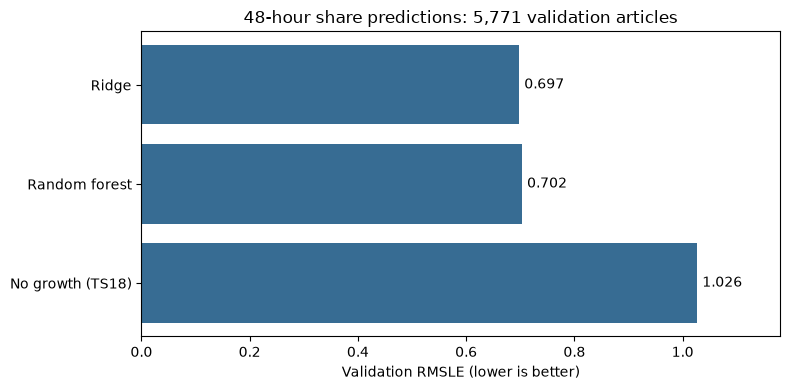

Ridge has the lowest RMSLE among these fitted models; Random forest has the lowest MAE in share counts. All scores use the same validation articles.


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.barh(
    model_comparison.index,
    model_comparison["RMSLE"],
    color="#376C93"
)
ax.invert_yaxis()
ax.set_xlim(0, model_comparison["RMSLE"].max() * 1.15)
ax.bar_label(bars, fmt="%.3f", padding=4)
ax.set_xlabel("Validation RMSLE (lower is better)")
ax.set_title(f"48-hour share predictions: {len(X_valid):,} validation articles")
plt.tight_layout()
plt.show()

rmsle_winner = model_comparison["RMSLE"].idxmin()
mae_winner = model_comparison["MAE (shares)"].idxmin()
print(
    f"{rmsle_winner} has the lowest RMSLE among these fitted models; "
    f"{mae_winner} has the lowest MAE in share counts. "
    "All scores use the same validation articles."
)

RMSLE compares errors on the `log(1 + shares)` scale. MAE measures the average absolute error in shares; RMSE gives more weight to large count errors. A model can win one metric and lose another.

Keep the model with the best validation RMSLE as the current candidate. These validation scores are used for model selection; they are not an unbiased final estimate. The test set has not been evaluated.